# M67 Star Cluster Membership Analysis

## DBSCAN-Based Candidate Membership Identification

This notebook investigates probable M67 members using
Gaia DR3 astrometric data and unsupervised clustering.

The workflow includes:

- Astronomical candidate selection
- Feature-space construction
- Feature scaling comparison
- DBSCAN parameter selection
- Clustering and noise analysis
- Astronomical validation of the detected groups

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

from pathlib import Path

## 1. Load Gaia DR3 Data

We load the raw Gaia dataset and verify its dimensions.
The raw data will remain unchanged throughout the analysis.

In [2]:
df = pd.read_csv(r"C:\Users\f.bahrami\Downloads\m67_gaia_dr3_raw.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (3655, 13)


,source_id,ra,dec,parallax,parallax_error,pmra,pmra_error,pmdec,pmdec_error,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,bp_rp
0,598615464931821824,132.980100,10.828845,1.426034,0.391541,-2.331372,0.418362,-4.489130,0.322635,19.728138,20.778519,18.590540,2.187979
1,598617320352895488,133.008603,10.888186,0.913913,0.083302,-5.764564,0.092492,3.588105,0.077137,17.326946,18.013742,16.547316,1.466427
2,598644224028253312,132.698094,10.915211,1.019217,0.489483,0.224477,0.609556,-4.799494,0.406793,19.968863,20.996855,18.857647,2.139208
3,598654772467716096,132.477913,10.890344,1.354095,0.249199,10.566326,0.251626,-12.743280,0.171140,18.785112,19.804697,17.813826,1.990871
4,598657628621169408,132.620801,11.019805,1.380839,0.051295,-5.123209,0.053391,-9.125101,0.038371,16.203362,16.835932,15.440519,1.395412


## 2. Reference Parameters of M67

We define approximate reference parameters for M67.

These values are used for exploratory comparison
and broad candidate selection, not as ground-truth labels.

In [3]:
m67_params = {
    "ra": 132.825,
    "dec": 11.800,
    "parallax": 1.15,
    "pmra": -10.96,
    "pmdec": -2.90
}

m67_params

{'ra': 132.825, 'dec': 11.8, 'parallax': 1.15, 'pmra': -10.96, 'pmdec': -2.9}

## 3. Initial Astronomical Candidate Selection

We apply broad astrometric selection criteria around
the reference parameters of M67.

This selection is intentionally broad and does not
represent final membership classification.

In [4]:
candidate_mask = (
    (df["parallax"].between(0.80, 1.50)) &
    (np.sqrt(
        (df["pmra"] - m67_params["pmra"])**2 +
        (df["pmdec"] - m67_params["pmdec"])**2
    ) < 2.5)
)

candidates = df.loc[candidate_mask].copy()

print("Initial dataset:", len(df))
print("Astrometric candidates:", len(candidates))
print("Candidate fraction:", len(candidates) / len(df))

Initial dataset: 3655
Astrometric candidates: 1606
Candidate fraction: 0.4393980848153215


In [5]:
candidates.describe()

,source_id,ra,dec,parallax,parallax_error,pmra,pmra_error,pmdec,pmdec_error,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,bp_rp
count,1.606000e+03,1606.000000,1606.000000,1606.000000,1606.000000,1606.000000,1606.000000,1606.000000,1606.000000,1606.000000,1606.000000,1606.000000,1606.000000
mean,6.042380e+17,132.854554,11.832339,1.161464,0.103385,-10.941249,0.107924,-2.916563,0.079287,15.925033,16.599714,15.172336,1.427379
std,2.133883e+15,0.293921,0.283918,0.103797,0.119794,0.398671,0.124994,0.374255,0.092118,2.353395,2.672742,2.134161,0.606834
min,5.986165e+17,131.900114,10.859685,0.900597,0.013184,-13.319950,0.013368,-5.342016,0.010105,7.948060,9.059734,6.900066,-0.524195
25%,6.048974e+17,132.700447,11.684697,1.112014,0.023763,-11.105070,0.024852,-3.056681,0.018195,14.006608,14.331501,13.521940,0.865497
50%,6.049176e+17,132.849209,11.820750,1.154471,0.048365,-10.965293,0.050304,-2.916387,0.037284,15.922528,16.468324,15.213364,1.271304
75%,6.049626e+17,133.002835,11.979216,1.201079,0.138108,-10.794614,0.143794,-2.767081,0.105597,17.926699,18.951279,16.927882,2.016827
max,6.081279e+17,133.823106,12.775521,1.498753,1.018703,-8.619778,0.994193,-0.572939,0.805298,19.992224,21.475515,20.289341,2.779228


Shape of total (3655, 13)
Shape of candidates (1606, 19)
Shape of m67_params:  {'ra': 132.825, 'dec': 11.8, 'parallax': 1.15, 'pmra': -10.96, 'pmdec': -2.9}


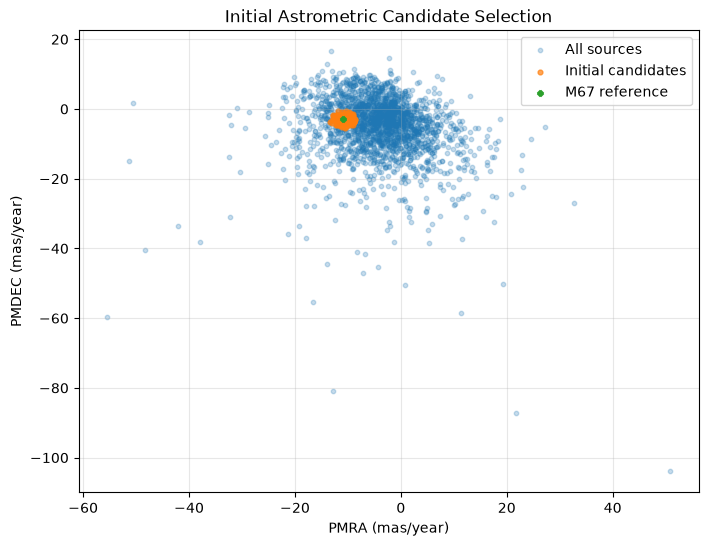

In [98]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["pmra"],
    df["pmdec"],
    s=10,
    alpha=0.25,
    label="All sources"
)

plt.scatter(
    candidates["pmra"],
    candidates["pmdec"],
    s=12,
    alpha=0.7,
    label="Initial candidates"
)

plt.scatter(
    m67_params["pmra"],
    m67_params["pmdec"],
    marker="x",
    s=10,
    linewidths=3,
    label="M67 reference"
)

plt.xlabel("PMRA (mas/year)")
plt.ylabel("PMDEC (mas/year)")
plt.title("Initial Astrometric Candidate Selection")

print("Shape of total",df.shape)
print("Shape of candidates",candidates.shape)
print("Shape of m67_params: ", m67_params)
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    r"F:\anaconda3\Fiverr\reports\figures\Initial_Astrometric_Candidate_Selection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Local Tangent Plane Coordinates

We convert RA and DEC into approximate local angular offsets.

The RA offset is corrected by cos(DEC_center)
to account for the angular scale difference in right ascension.

The resulting coordinates are expressed in degrees.

In [8]:
center_ra = m67_params["ra"]
center_dec = m67_params["dec"]

candidates["x_deg"] = (
    (candidates["ra"] - center_ra)
    * np.cos(np.radians(center_dec))
)

candidates["y_deg"] = (
    candidates["dec"] - center_dec
)

candidates[["ra", "dec", "x_deg", "y_deg"]].head()

,ra,dec,x_deg,y_deg
10,133.030545,10.993079,0.201202,-0.806921
19,132.951475,11.302158,0.123803,-0.497842
20,132.759041,11.228045,-0.064565,-0.571955
22,132.337174,11.163225,-0.477517,-0.636775
27,132.692721,11.339832,-0.129484,-0.460168


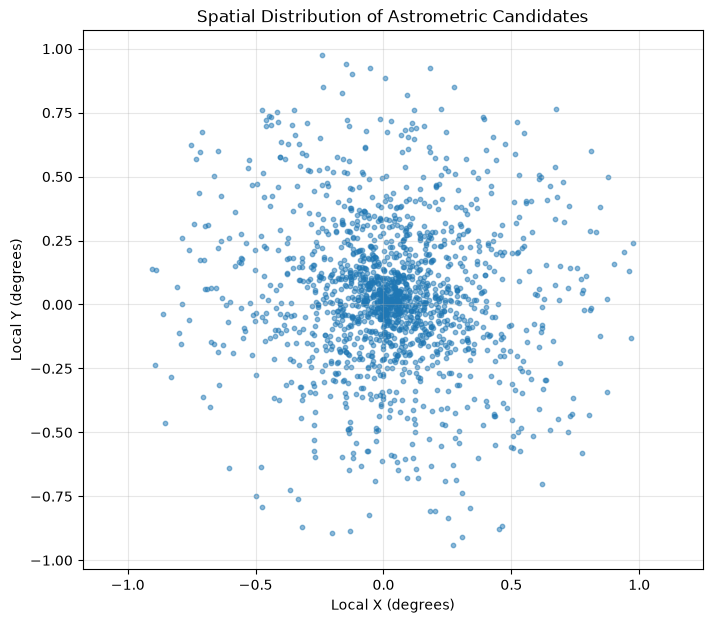

In [99]:
plt.figure(figsize=(8, 7))

plt.scatter(
    candidates["x_deg"],
    candidates["y_deg"],
    s=10,
    alpha=0.5
)

plt.xlabel("Local X (degrees)")
plt.ylabel("Local Y (degrees)")

plt.title("Spatial Distribution of Astrometric Candidates")

plt.axis("equal") # why "equal"? because we want to equal the scale of X and Y axis
plt.grid(alpha=0.3)

plt.savefig(
    r"F:\anaconda3\Fiverr\reports\figures\Spatial_Distribution_Astrometric_Candidate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5. Feature Space 1 — Proper Motion

The first clustering feature space consists of
the two proper motion components.

This space investigates kinematic grouping
without including parallax or spatial position.

In [15]:
features_pm = [
    "pmra",
    "pmdec"
]

X_pm = candidates[features_pm].copy()

X_pm.head()

,pmra,pmdec
10,-10.811076,-2.866313
19,-11.181614,-2.780437
20,-10.566526,-2.698305
22,-10.909533,-2.701499
27,-11.041189,-2.904162


## 6. Feature Space 2 — Proper Motion and Parallax

We add parallax to the proper motion features.

This feature space combines kinematic and distance-related
information for cluster membership investigation.

In [16]:
features_pm_parallax = [
    "pmra",
    "pmdec",
    "parallax"
]

X_pm_parallax = candidates[features_pm_parallax].copy()

X_pm_parallax.head()

,pmra,pmdec,parallax
10,-10.811076,-2.866313,1.126253
19,-11.181614,-2.780437,1.138730
20,-10.566526,-2.698305,1.340247
22,-10.909533,-2.701499,1.085280
27,-11.041189,-2.904162,1.126999


## 7. Feature Space 3 — Five-Dimensional Astrometry

We construct a five-dimensional astrometric feature space:

- Local X position
- Local Y position
- PMRA
- PMDEC
- Parallax

This combines spatial, kinematic, and distance-related information.

In [17]:
features_5d = [
    "x_deg",
    "y_deg",
    "pmra",
    "pmdec",
    "parallax"
]

X_5d = candidates[features_5d].copy()

X_5d.head()

,x_deg,y_deg,pmra,pmdec,parallax
10,0.201202,-0.806921,-10.811076,-2.866313,1.126253
19,0.123803,-0.497842,-11.181614,-2.780437,1.138730
20,-0.064565,-0.571955,-10.566526,-2.698305,1.340247
22,-0.477517,-0.636775,-10.909533,-2.701499,1.085280
27,-0.129484,-0.460168,-11.041189,-2.904162,1.126999


In [22]:
feature_spaces = {
    "PM Only": X_pm,
    "PM + Parallax": X_pm_parallax,
    "5D Astrometry": X_5d
}

for name, X in feature_spaces.items():
    print(f"{name}:")
    #print("X:", X.head())
    print("Shape:", X.shape)
    print("Features:", X.columns.tolist())
    print("-" * 50)

PM Only:
Shape: (1606, 2)
Features: ['pmra', 'pmdec']
--------------------------------------------------
PM + Parallax:
Shape: (1606, 3)
Features: ['pmra', 'pmdec', 'parallax']
--------------------------------------------------
5D Astrometry:
Shape: (1606, 5)
Features: ['x_deg', 'y_deg', 'pmra', 'pmdec', 'parallax']
--------------------------------------------------


## 8. Feature Scaling Comparison

We compare StandardScaler and RobustScaler.

StandardScaler uses mean and standard deviation.
RobustScaler uses the median and interquartile range.

Both transformations are evaluated because astrometric
features may contain outliers.

StandardScaler
\[
z=\frac{x-\mu}{\sigma}
\]

میانگین را به صفر و انحراف معیار را به یک نزدیک می‌کند.


RobustScaler
\[
z=\frac{x-Q_1}{Q_3-Q_1}
\]

از Median و IQR استفاده می‌کند و نسبت به Outlierها مقاوم‌تر است.

    

In [24]:
scalers = {
    "StandardScaler": StandardScaler(),
    "RobustScaler": RobustScaler()
}

scaled_spaces = {}

for space_name, X in feature_spaces.items():

    for scaler_name, scaler in scalers.items():

        X_scaled = scaler.fit_transform(X)

        scaled_spaces[(space_name, scaler_name)] = X_scaled

        print(
            space_name,
            "|",
            scaler_name,
            "|",
            X_scaled.shape
        )

PM Only | StandardScaler | (1606, 2)
PM Only | RobustScaler | (1606, 2)
PM + Parallax | StandardScaler | (1606, 3)
PM + Parallax | RobustScaler | (1606, 3)
5D Astrometry | StandardScaler | (1606, 5)
5D Astrometry | RobustScaler | (1606, 5)


In [28]:
scaled_pm = pd.DataFrame(
    scaled_spaces[("PM Only", "StandardScaler")],
    columns=features_pm,
    index=X_pm.index
)

scaled_pm.describe()

,pmra,pmdec
count,1.606000e+03,1.606000e+03
mean,-2.234272e-16,6.249325e-16
std,1.000311e+00,1.000311e+00
min,-5.968431e+00,-6.482767e+00
25%,-4.110460e-01,-3.745091e-01
50%,-6.032843e-02,4.716952e-04
75%,3.679234e-01,3.995366e-01
max,5.824833e+00,6.264053e+00


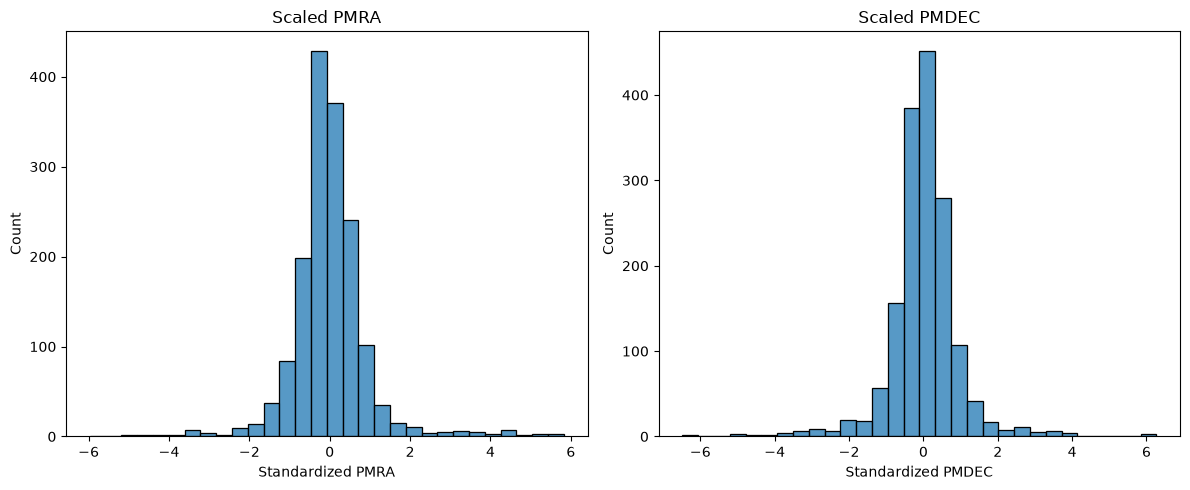

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(
    scaled_pm["pmra"],
    bins=30,
    ax=axes[0]
)

axes[0].set_title("Scaled PMRA")
axes[0].set_xlabel("Standardized PMRA")

sns.histplot(
    scaled_pm["pmdec"],
    bins=30,
    ax=axes[1]
)

axes[1].set_title("Scaled PMDEC")
axes[1].set_xlabel("Standardized PMDEC")

plt.tight_layout()
plt.show()

## 9. DBSCAN min_samples Selection

We begin with min_samples = 10 as an exploratory value.

The parameter will be tested for sensitivity
rather than treated as a fixed scientific optimum.

In [30]:
def plot_k_distance(X, k=10, title="K-distance plot"):

    neighbors = NearestNeighbors(
        n_neighbors=k
    )

    neighbors.fit(X)

    distances, indices = neighbors.kneighbors(X)

    k_distances = np.sort(distances[:, -1])

    plt.figure(figsize=(8, 5))

    plt.plot(k_distances)

    plt.xlabel("Points sorted by distance")
    plt.ylabel(f"Distance to {k}-th nearest neighbor")
    plt.title(title)

    plt.grid(alpha=0.3)

    plt.show()

    return k_distances

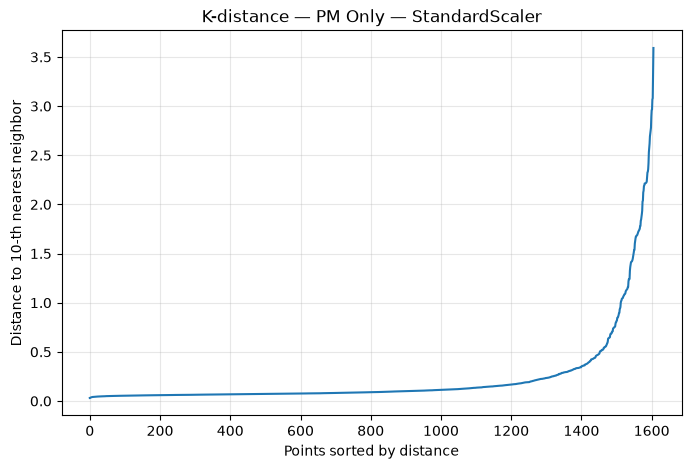

In [31]:
k_dist_pm = plot_k_distance(
    scaled_spaces[("PM Only", "StandardScaler")],
    k=10,
    title="K-distance — PM Only — StandardScaler"
)

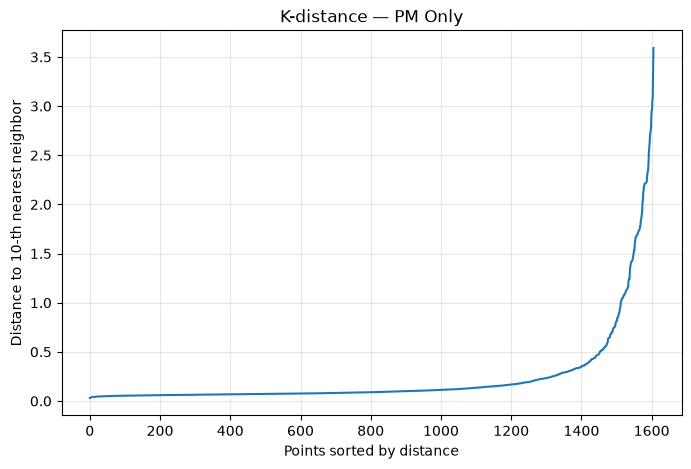

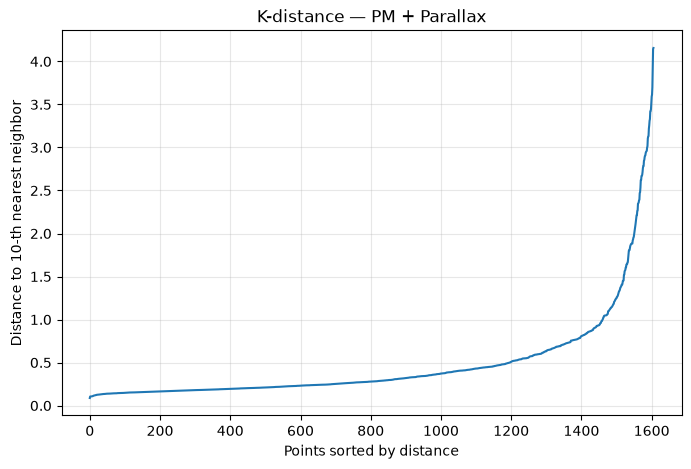

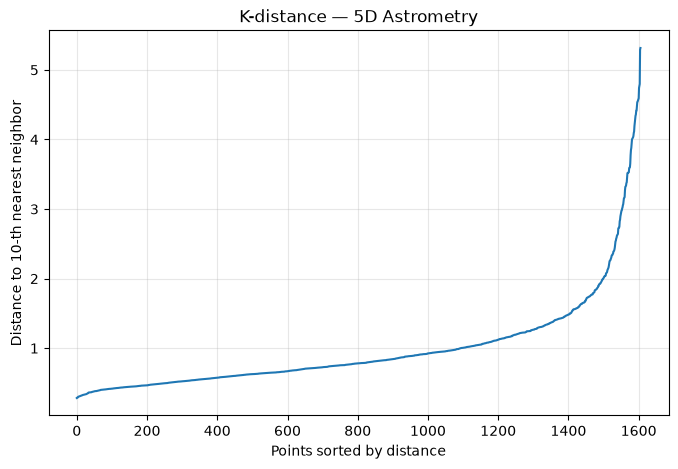

In [32]:
for space_name in feature_spaces:

    X_scaled = scaled_spaces[
        (space_name, "StandardScaler")
    ]

    plot_k_distance(
        X_scaled,
        k=10,
        title=f"K-distance — {space_name}"
    )

## 10. First DBSCAN Experiment — Proper Motion

We apply DBSCAN to the standardized PMRA and PMDEC features.

The initial epsilon is set to 0.3 for experimentation.
This value must be evaluated using the K-distance plot
and cluster structure.

# ** On "PM Only"

In [33]:
eps_pm = 0.3
min_samples_pm = 10

dbscan_pm = DBSCAN(
    eps=eps_pm,
    min_samples=min_samples_pm
)

labels_pm = dbscan_pm.fit_predict(
    scaled_spaces[("PM Only", "StandardScaler")]
)

candidates["dbscan_pm_label"] = labels_pm

print("DBSCAN labels:", np.unique(labels_pm))

DBSCAN labels: [-1  0  1  2]


In [34]:
cluster_counts_pm = (
    candidates["dbscan_pm_label"]
    .value_counts()
    .sort_index()
)

cluster_counts_pm

dbscan_pm_label
-1     186
 0    1407
 1       5
 2       8
Name: count, dtype: int64

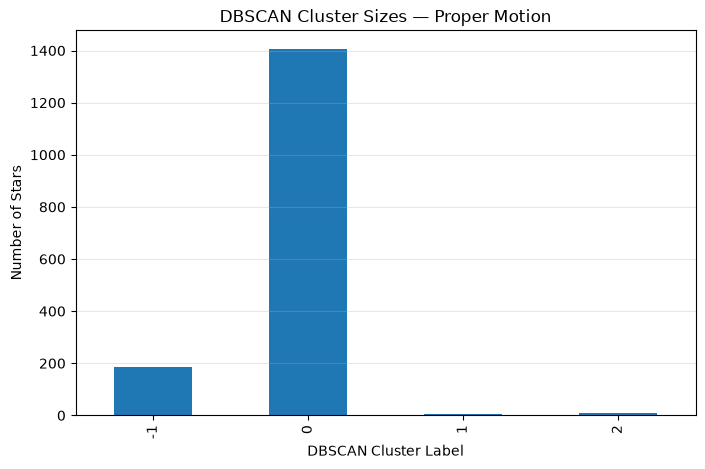

In [35]:
plt.figure(figsize=(8, 5))

cluster_counts_pm.plot(kind="bar")

plt.xlabel("DBSCAN Cluster Label")
plt.ylabel("Number of Stars")
plt.title("DBSCAN Cluster Sizes — Proper Motion")

plt.grid(axis="y", alpha=0.3)

plt.show()

In [36]:
n_clusters_pm = len(
    set(labels_pm) - {-1}
)

n_noise_pm = np.sum(
    labels_pm == -1
)

noise_percentage_pm = (
    n_noise_pm / len(labels_pm) * 100
)

print("Number of clusters:", n_clusters_pm)
print("Number of noise points:", n_noise_pm)
print(f"Noise percentage: {noise_percentage_pm:.2f}%")

Number of clusters: 3
Number of noise points: 186
Noise percentage: 11.58%


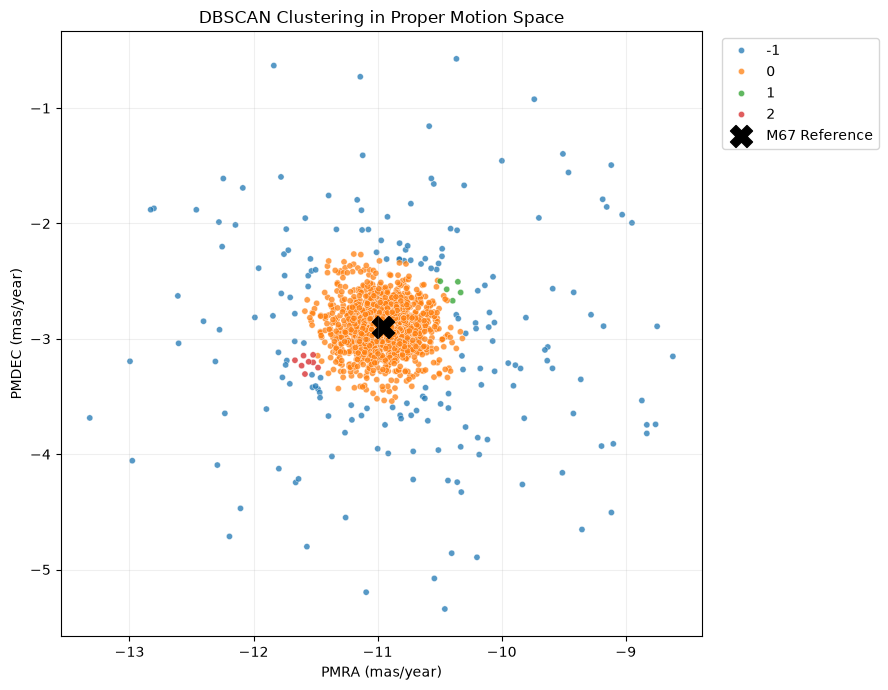

In [37]:
# drawing clusters in Proper Motion Space
plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=candidates,
    x="pmra",
    y="pmdec",
    hue="dbscan_pm_label",
    palette="tab10",
    s=20,
    alpha=0.75
)

plt.scatter(
    m67_params["pmra"],
    m67_params["pmdec"],
    marker="X",
    s=250,
    color="black",
    label="M67 Reference"
)

plt.title("DBSCAN Clustering in Proper Motion Space")
plt.xlabel("PMRA (mas/year)")
plt.ylabel("PMDEC (mas/year)")

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# ** "Feature Space"

## 11. DBSCAN Feature Space Comparison

We compare DBSCAN results across three feature spaces:

1. Proper Motion
2. Proper Motion + Parallax
3. Five-dimensional Astrometry

Each feature space is standardized independently.

The same initial eps and min_samples are used for
a controlled preliminary comparison, but eps must be
re-tuned for each space using its own K-distance plot.

In [38]:
dbscan_experiments = {}

initial_eps = 0.3
initial_min_samples = 10

for space_name in feature_spaces:

    X_scaled = scaled_spaces[
        (space_name, "StandardScaler")
    ]

    model = DBSCAN(
        eps=initial_eps,
        min_samples=initial_min_samples
    )

    labels = model.fit_predict(X_scaled)

    dbscan_experiments[space_name] = labels

    print("\nFeature Space:", space_name)
    print("Clusters:", len(set(labels) - {-1}))
    print("Noise:", np.sum(labels == -1))


Feature Space: PM Only
Clusters: 3
Noise: 186

Feature Space: PM + Parallax
Clusters: 2
Noise: 596

Feature Space: 5D Astrometry
Clusters: 2
Noise: 1572


In [39]:
# comparing DBSCAN
dbscan_comparison = []

for space_name, labels in dbscan_experiments.items():

    n_clusters = len(set(labels) - {-1})

    n_noise = np.sum(labels == -1)

    noise_pct = n_noise / len(labels) * 100

    dbscan_comparison.append({
        "feature_space": space_name,
        "n_clusters": n_clusters,
        "n_noise": n_noise,
        "noise_percentage": noise_pct
    })

dbscan_comparison = pd.DataFrame(dbscan_comparison)

dbscan_comparison

,feature_space,n_clusters,n_noise,noise_percentage
0,PM Only,3,186,11.581569
1,PM + Parallax,2,596,37.110834
2,5D Astrometry,2,1572,97.882939


## 12. Noise Investigation

DBSCAN noise points are sources that do not satisfy
the density-based cluster criteria under the selected parameters.

Noise does not necessarily imply poor data quality
or non-membership in M67.

In [40]:
noise_pm = candidates.loc[
    candidates["dbscan_pm_label"] == -1
].copy()

clustered_pm = candidates.loc[
    candidates["dbscan_pm_label"] != -1
].copy()

print("Noise sources:", len(noise_pm))
print("Clustered sources:", len(clustered_pm))

Noise sources: 186
Clustered sources: 1420


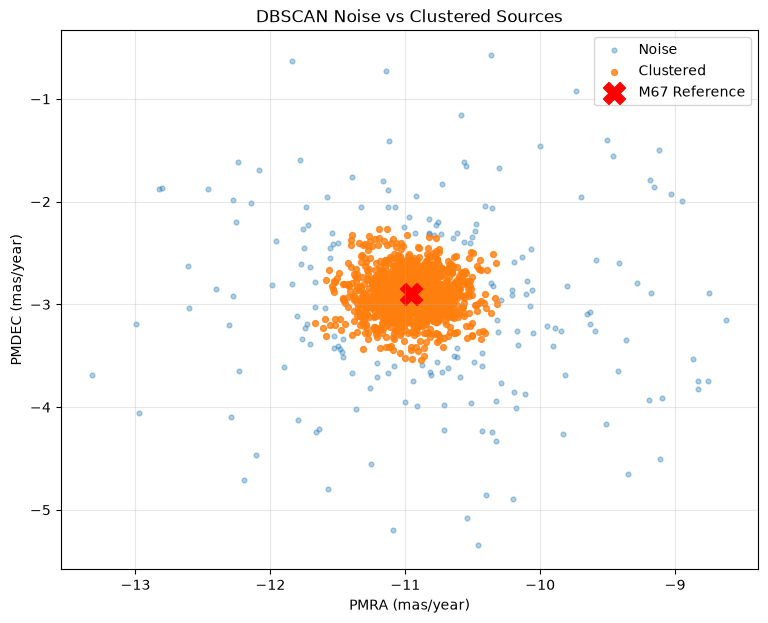

In [41]:
# In Proper Motion
plt.figure(figsize=(9, 7))

plt.scatter(
    noise_pm["pmra"],
    noise_pm["pmdec"],
    s=12,
    alpha=0.35,
    label="Noise"
)

plt.scatter(
    clustered_pm["pmra"],
    clustered_pm["pmdec"],
    s=18,
    alpha=0.8,
    label="Clustered"
)

plt.scatter(
    m67_params["pmra"],
    m67_params["pmdec"],
    marker="X",
    s=250,
    color="red",
    label="M67 Reference"
)

plt.xlabel("PMRA (mas/year)")
plt.ylabel("PMDEC (mas/year)")
plt.title("DBSCAN Noise vs Clustered Sources")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [42]:
cluster_analysis_pm = (
    candidates[candidates["dbscan_pm_label"] != -1]
    .groupby("dbscan_pm_label")
    .agg(
        n_stars=("source_id", "count"),
        mean_parallax=("parallax", "mean"),
        median_parallax=("parallax", "median"),
        mean_pmra=("pmra", "mean"),
        median_pmra=("pmra", "median"),
        mean_pmdec=("pmdec", "mean"),
        median_pmdec=("pmdec", "median"),
        mean_g_mag=("phot_g_mean_mag", "mean"),
        mean_bp_rp=("bp_rp", "mean")
    )
)

cluster_analysis_pm

,n_stars,mean_parallax,median_parallax,mean_pmra,median_pmra,mean_pmdec,median_pmdec,mean_g_mag,mean_bp_rp
dbscan_pm_label,,,,,,,,,
0,1407,1.159908,1.153299,-10.960565,-10.971287,-2.907618,-2.915138,15.834419,1.407841
1,5,1.163251,1.179170,-10.403140,-10.394535,-2.569012,-2.570697,15.408091,1.164473
2,8,1.150425,1.092275,-11.566968,-11.570530,-3.207728,-3.201734,16.830501,1.666031


## for finding the best cluster we should find a cluster with nearest mean for Parallax, PMRA, PMDEC and these features for the center of the cluster which is :
* Parallax  1.15 mas

* PMRA  -10.96 mas/year

* PMDEC  -2.90 mas/year


## 13. DBSCAN Parameter Optimization

The initial DBSCAN parameters are exploratory.

We revisit epsilon using K-distance plots for each feature space
and compare clustering outcomes across multiple parameter values.

No single parameter combination is assumed to be optimal
without inspecting the resulting cluster structure.

In [43]:
eps_values = [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]

min_samples_values = [5, 10, 15]

X_pm_scaled = scaled_spaces[
    ("PM Only", "StandardScaler")
]

results = []

for eps in eps_values:

    for min_samples in min_samples_values:

        model = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = model.fit_predict(X_pm_scaled)

        n_clusters = len(set(labels) - {-1})
        n_noise = np.sum(labels == -1)

        results.append({
            "eps": eps,
            "min_samples": min_samples,
            "n_clusters": n_clusters,
            "n_noise": n_noise,
            "noise_percentage": n_noise / len(labels) * 100
        })

dbscan_tuning_results = pd.DataFrame(results)

dbscan_tuning_results


,eps,min_samples,n_clusters,n_noise,noise_percentage
0,0.15,5,6,258,16.064757
1,0.15,10,2,366,22.789539
2,0.15,15,1,438,27.272727
3,0.20,5,4,205,12.764633
4,0.20,10,1,297,18.493151
5,0.20,15,1,333,20.734745
6,0.25,5,2,174,10.834371
7,0.25,10,1,235,14.632628
8,0.25,15,1,286,17.808219
9,0.30,5,2,143,8.904110


In [47]:
dbscan_tuning_results['noise_percentage'].min()

5.72851805728518

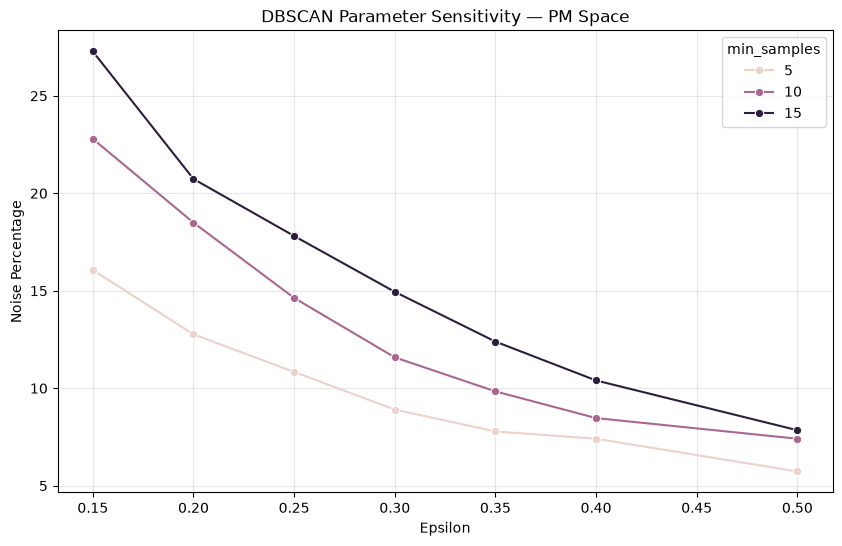

In [48]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=dbscan_tuning_results,
    x="eps",
    y="noise_percentage",
    hue="min_samples",
    marker="o"
)

plt.title("DBSCAN Parameter Sensitivity — PM Space")
plt.xlabel("Epsilon")
plt.ylabel("Noise Percentage")

plt.grid(alpha=0.3)
plt.show()

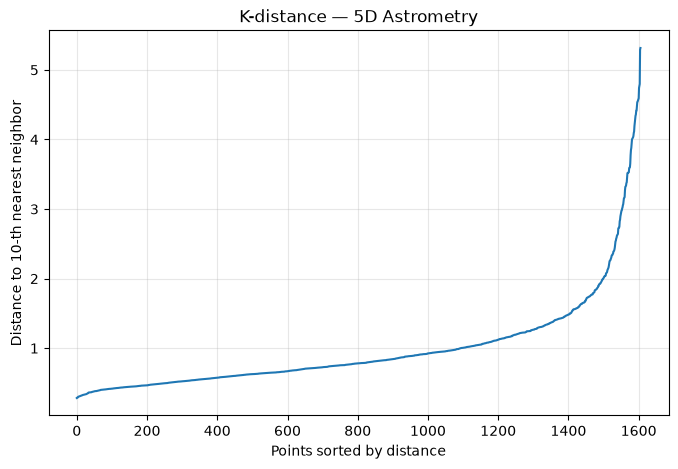

In [49]:
X_5d_scaled = scaled_spaces[
    ("5D Astrometry", "StandardScaler")
]

k_dist_5d = plot_k_distance(
    X_5d_scaled,
    k=10,
    title="K-distance — 5D Astrometry"
)

In [65]:
eps_5d = 1.8
min_samples_5d = 10

dbscan_5d = DBSCAN(
    eps=eps_5d,
    min_samples=min_samples_5d
)

labels_5d = dbscan_5d.fit_predict(X_5d_scaled)

candidates["dbscan_5d_label"] = labels_5d

print("Clusters:", len(set(labels_5d) - {-1}))
print("Noise:", np.sum(labels_5d == -1))

Clusters: 1
Noise: 80


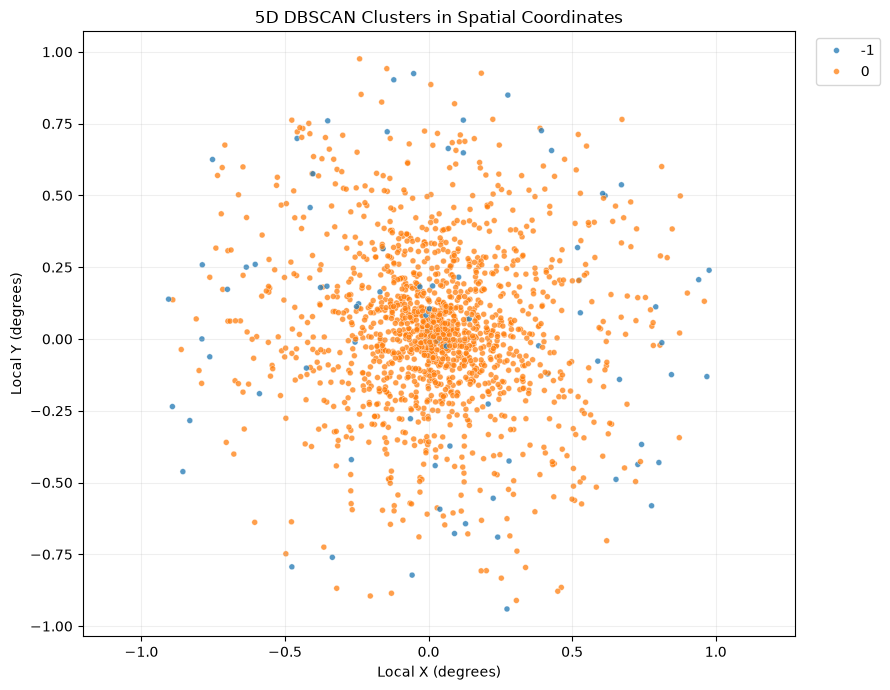

In [97]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=candidates,
    x="x_deg",
    y="y_deg",
    hue="dbscan_5d_label",
    palette="tab10",
    s=18,
    alpha=0.75
)

plt.xlabel("Local X (degrees)")
plt.ylabel("Local Y (degrees)")

plt.title("5D DBSCAN Clusters in Spatial Coordinates")

plt.axis("equal")
plt.grid(alpha=0.2)

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

plt.savefig(
    r"F:\anaconda3\Fiverr\reports\figures\5D_DBSCAN_Clusters_Spatial_Coordinates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

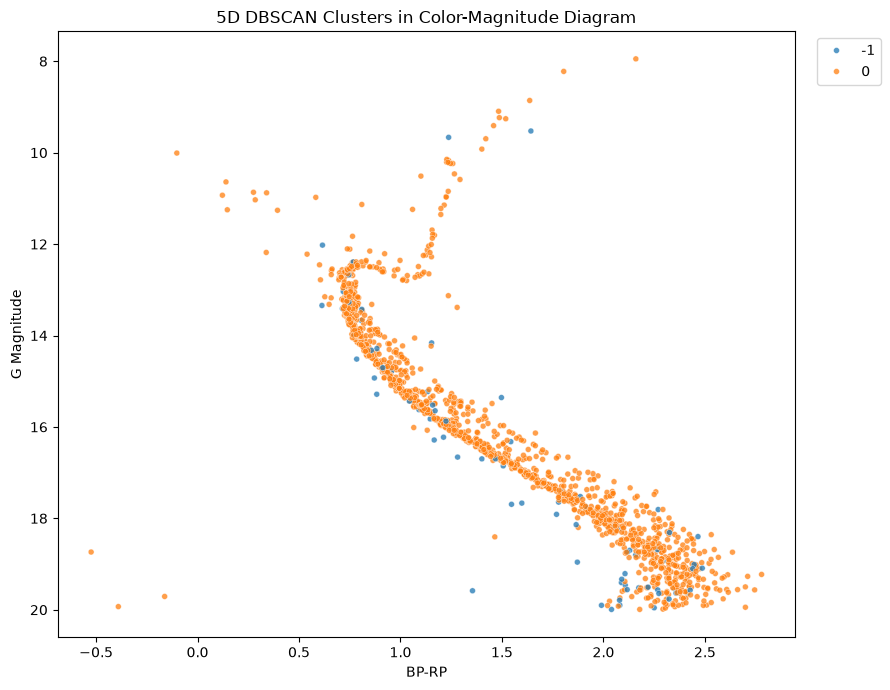

In [96]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=candidates,
    x="bp_rp",
    y="phot_g_mean_mag",
    hue="dbscan_5d_label",
    palette="tab10",
    s=18,
    alpha=0.75
)

plt.gca().invert_yaxis()

plt.xlabel("BP-RP")
plt.ylabel("G Magnitude")

plt.title("5D DBSCAN Clusters in Color-Magnitude Diagram")

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

plt.savefig(
    r"F:\anaconda3\Fiverr\reports\figures\5D_DBSCAN_Clusters_CMD.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 14. Gaussian Mixture Model

We use a Gaussian Mixture Model to investigate
probabilistic grouping in astrometric feature space.

The initial feature set contains:

- PMRA
- PMDEC
- Parallax

The features are standardized before fitting.

In [68]:
from sklearn.mixture import GaussianMixture

gmm_features = [
    "pmra",
    "pmdec",
    "parallax"
]

X_gmm = candidates[gmm_features].copy()

gmm_scaler = StandardScaler()

X_gmm_scaled = gmm_scaler.fit_transform(X_gmm)

X_gmm_scaled.shape

(1606, 3)

# [BIC=-2ln(L)+kln(n)]
(L) → Likelihood 
(k) →  number of Parameters
(n) →  number of Samples

In [69]:
bic_values = []
aic_values = []
component_range = range(1, 9)

for n_components in component_range:

    gmm_model = GaussianMixture(
        n_components=n_components,
        covariance_type="full",
        random_state=42,
        n_init=5
    )

    gmm_model.fit(X_gmm_scaled)

    bic_values.append(gmm_model.bic(X_gmm_scaled))
    aic_values.append(gmm_model.aic(X_gmm_scaled))

In [70]:
gmm_model_selection = pd.DataFrame({
    "n_components": list(component_range),
    "BIC": bic_values,
    "AIC": aic_values
})

gmm_model_selection

,n_components,BIC,AIC
0,1,13723.586329,13675.152812
1,2,11847.407357,11745.158821
2,3,11585.220793,11429.157238
3,4,11618.011671,11408.133098
4,5,11664.188909,11400.495316
5,6,11748.881617,11431.373005
6,7,11793.411800,11422.088169
7,8,11856.402002,11431.263353


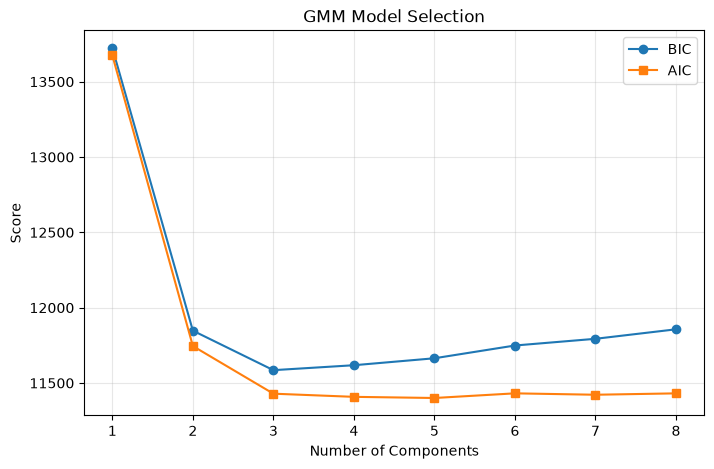

In [71]:
plt.figure(figsize=(8, 5))

plt.plot(
    gmm_model_selection["n_components"],
    gmm_model_selection["BIC"],
    marker="o",
    label="BIC"
)

plt.plot(
    gmm_model_selection["n_components"],
    gmm_model_selection["AIC"],
    marker="s",
    label="AIC"
)

plt.xlabel("Number of Components")
plt.ylabel("Score")

plt.title("GMM Model Selection")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

## we usually choose the lowest component as the best and try on it

In [74]:
best_n_components = 3

gmm_final = GaussianMixture(
    n_components=best_n_components,
    covariance_type="full",
    random_state=42,
    n_init=10
)

gmm_final.fit(X_gmm_scaled)

gmm_labels = gmm_final.predict(X_gmm_scaled)

gmm_probabilities = gmm_final.predict_proba(X_gmm_scaled)

candidates["gmm_label"] = gmm_labels

In [75]:
gmm_means_original = gmm_scaler.inverse_transform(
    gmm_final.means_
)

gmm_component_summary = pd.DataFrame(
    gmm_means_original,
    columns=gmm_features
)

gmm_component_summary["component"] = range(
    best_n_components
)

gmm_component_summary

,pmra,pmdec,parallax,component
0,-10.962695,-2.912979,1.151448,0
1,-10.958856,-2.899685,1.170620,1
2,-10.791313,-2.988208,1.173381,2


In [76]:
reference_vector = np.array([
    m67_params["pmra"],
    m67_params["pmdec"],
    m67_params["parallax"]
])

component_distances = np.sqrt(
    np.sum(
        (
            gmm_means_original -
            reference_vector
        )**2,
        axis=1
    )
)

component_distances

array([0.01333515, 0.02065428, 0.19178778])

In [78]:
component_distances = np.sqrt(
    np.sum(
        (gmm_means_original - reference_vector) ** 2,
        axis=1
    )
)
component_distances

array([0.01333515, 0.02065428, 0.19178778])

In [80]:
# using Standardization
reference_scaled = gmm_scaler.transform(
    pd.DataFrame(
        [reference_vector],
        columns=gmm_features
    )
)

component_distances_scaled = np.sqrt(
    np.sum(
        (
            gmm_final.means_ -
            reference_scaled
        )**2,
        axis=1
    )
)

component_distances_scaled

array([0.03800112, 0.19874246, 0.5343211 ])

In [81]:
m67_component = np.argmin(
    component_distances_scaled
)

print("Component closest to M67 reference:", m67_component)

Component closest to M67 reference: 0


In [86]:
candidates["gmm_m67_probability"] = (
    gmm_probabilities[:, m67_component]
)

candidates[
    [
        "source_id",
        "pmra",
        "pmdec",
        "parallax",
        "gmm_label",
        "gmm_m67_probability"
    ]
].head()

,source_id,pmra,pmdec,parallax,gmm_label,gmm_m67_probability
10,598671230782456192,-10.811076,-2.866313,1.126253,0,0.885732
19,598692675554477056,-11.181614,-2.780437,1.138730,0,0.828333
20,598693976929340800,-10.566526,-2.698305,1.340247,1,0.000092
22,598853788367658624,-10.909533,-2.701499,1.085280,0,0.648071
27,598883337742544128,-11.041189,-2.904162,1.126999,0,0.906886


In [83]:
gmm_candidates_70 = candidates.loc[
    candidates["gmm_m67_probability"] >= 0.70
].copy()

gmm_candidates_90 = candidates.loc[
    candidates["gmm_m67_probability"] >= 0.90
].copy()

print("Candidates with probability >= 0.70:", len(gmm_candidates_70))
print("Candidates with probability >= 0.90:", len(gmm_candidates_90))

Candidates with probability >= 0.70: 725
Candidates with probability >= 0.90: 139


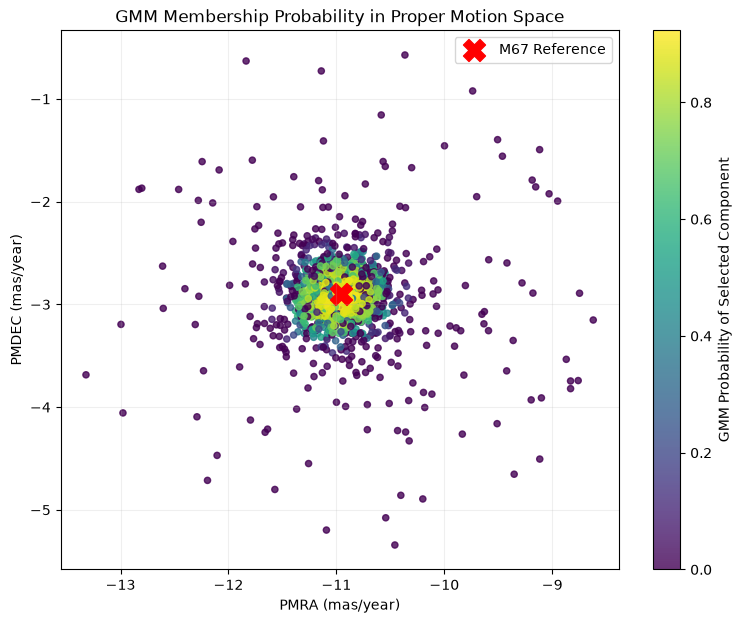

In [95]:
plt.figure(figsize=(9, 7))

scatter = plt.scatter(
    candidates["pmra"],
    candidates["pmdec"],
    c=candidates["gmm_m67_probability"],
    cmap="viridis",
    s=20,
    alpha=0.8
)

plt.colorbar(
    scatter,
    label="GMM Probability of Selected Component"
)

plt.scatter(
    m67_params["pmra"],
    m67_params["pmdec"],
    marker="X",
    s=250,
    color="red",
    label="M67 Reference"
)

plt.xlabel("PMRA (mas/year)")
plt.ylabel("PMDEC (mas/year)")

plt.title("GMM Membership Probability in Proper Motion Space")

plt.legend()
plt.grid(alpha=0.2)

plt.savefig(
    r"F:\anaconda3\Fiverr\reports\figures\GMM_Membership_Probability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [87]:
# Comparing DBSCAN and GMM
comparison_df = candidates[
    [
        "source_id",
        "dbscan_5d_label",
        "gmm_label",
        "gmm_m67_probability"
    ]
].copy()

comparison_df["gmm_candidate_70"] = (
    comparison_df["gmm_m67_probability"] >= 0.70
)

comparison_df["dbscan_clustered"] = (
    comparison_df["dbscan_5d_label"] != -1
)

comparison_df.head()

,source_id,dbscan_5d_label,gmm_label,gmm_m67_probability,gmm_candidate_70,dbscan_clustered
10,598671230782456192,0,0,0.885732,True,True
19,598692675554477056,0,0,0.828333,True,True
20,598693976929340800,0,1,0.000092,False,True
22,598853788367658624,0,0,0.648071,False,True
27,598883337742544128,0,0,0.906886,True,True


In [88]:
agreement_summary = pd.crosstab(
    comparison_df["dbscan_clustered"],
    comparison_df["gmm_candidate_70"],
    rownames=["DBSCAN Clustered"],
    colnames=["GMM Probability >= 0.70"]
)

agreement_summary

GMM Probability >= 0.70,False,True
DBSCAN Clustered,,
False,80,0
True,801,725


In [91]:
final_candidates = candidates.loc[
    candidates["gmm_m67_probability"] >= 0.70
].copy()

final_candidates = final_candidates.sort_values(
    "gmm_m67_probability",
    ascending=False
)

final_candidates.head(20)

,source_id,ra,dec,parallax,parallax_error,pmra,pmra_error,pmdec,pmdec_error,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,bp_rp,x_deg,y_deg,dbscan_pm_label,dbscan_5d_label,gmm_label,gmm_m67_probability
1089,605107810506158848,133.221563,12.533796,1.150784,0.030792,-10.974195,0.032595,-2.929130,0.024077,15.166164,15.577381,14.589964,0.987417,0.388183,0.733796,0,0,0,0.923161
285,604901407262883456,133.222086,11.710160,1.148385,0.077574,-10.942936,0.080159,-2.894307,0.058980,17.167074,17.973955,16.297785,1.676170,0.388695,-0.089840,0,0,0,0.922365
2285,604913952863074688,132.722631,11.742953,1.155721,0.017864,-10.961262,0.019050,-2.904500,0.013874,13.447743,13.771416,12.960517,0.810899,-0.100206,-0.057047,0,0,0,0.922353
3260,604988376056169088,132.564481,12.154437,1.146673,0.068647,-10.982577,0.069998,-2.898541,0.051486,16.781284,17.478111,15.972361,1.505751,-0.255014,0.354437,0,0,0,0.922293
1559,604921202767809664,132.870606,11.870137,1.153063,0.028192,-10.959049,0.029504,-2.886235,0.021305,14.762794,15.179295,14.175256,1.004039,0.044642,0.070137,0,0,0,0.921969
632,604902923387005440,132.979756,11.661155,1.152311,0.021905,-10.963047,0.023760,-2.957485,0.016723,14.207137,14.533503,13.715858,0.817645,0.151486,-0.138845,0,0,0,0.921872
3579,604921168408082048,132.843307,11.858108,1.155399,0.017517,-10.971762,0.017608,-2.957944,0.012252,13.148642,13.441898,12.694894,0.747004,0.017921,0.058108,0,0,0,0.921242
3427,604973085972551296,132.769533,12.072006,1.148557,0.016311,-10.932152,0.016500,-2.959828,0.012877,13.405049,13.697409,12.953720,0.743689,-0.054294,0.272006,0,0,0,0.920908
2679,604920202039656064,132.997962,11.917997,1.157571,0.018706,-10.974584,0.019367,-2.954178,0.013333,10.210122,10.752384,9.518223,1.234161,0.169307,0.117997,0,0,0,0.920829
1308,604947865924535808,133.025226,12.029341,1.138710,0.037209,-10.987354,0.037594,-2.932096,0.028422,15.678186,16.175762,15.027198,1.148564,0.195994,0.229341,0,0,0,0.920624


In [92]:
# Saving results
output_dir = Path("../Fiverr/data/processed")

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

candidates.to_csv(
    output_dir / "m67_all_candidates_with_labels.csv",
    index=False
)

In [93]:
final_candidates.to_csv(
    output_dir / "m67_gmm_candidates_70pct.csv",
    index=False
)

In [94]:
comparison_df.to_csv(
    output_dir / "m67_dbscan_gmm_comparison.csv",
    index=False
)